# 04 · Reliability classifier (stretch goal)

**Problem:** ~35% of listings have **no reviews**, so a guest can't tell whether they are real, active places or abandoned/fake ones.

**Idea:** learn from listings that *do* have a history what an active listing looks like, then score the ones without reviews.

- **Target:** `active_ltm` = had at least one review in the last 12 months (≈ booked recently).
- **Train on:** listings with at least one review ever (we know their history).
- **Inputs:** only things a brand-new listing also has. **No review columns** (that would leak the answer).
- **Extra input:** the price gap from notebook 02 (out-of-fold, so no leakage). Over-priced listings may get fewer bookings.
- **Models:** Logistic Regression, Random Forest, XGBoost, MLP. **Metrics:** ROC-AUC and F1.

Output: `reliability` (0–1) for every listing, used in the app's Trust score.

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()          # repo root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT))
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for p in (PROCESSED, MODELS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
SEED = 42
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, f1_score, classification_report, RocCurveDisplay
from xgboost import XGBClassifier

In [2]:
df = pd.read_parquet(PROCESSED / "listings_priced.parquet")
feats = json.load(open(PROCESSED / "feature_lists.json"))
CAT = feats["cat"]
NUM = [c for c in feats["num"] if c not in feats["review"]] + ["price_gap", "log_price"]
assert not set(NUM) & set(feats["review"]), "review columns must not be inputs"

hist = df[df["number_of_reviews"] > 0].reset_index(drop=True)   # listings with a known history
X, y = hist[CAT + NUM], hist["active_ltm"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(X_train):,} · test {len(X_test):,} · positive share {y.mean():.1%}")

train 12,907 · test 3,227 · positive share 73.9%


In [3]:
pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CAT),
    ("num", StandardScaler(), NUM),
])
models = {
    "Baseline (always 'active')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1,
                                            class_weight="balanced", random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.7, tree_method="hist", n_jobs=-1, random_state=SEED,
                             scale_pos_weight=(1 - y_train.mean()) / y_train.mean()),
    "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-4, early_stopping=True,
                         max_iter=200, random_state=SEED),
}
results, fitted = {}, {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)]).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    results[name] = {"ROC_AUC": roc_auc_score(y_test, proba), "F1": f1_score(y_test, proba >= 0.5)}
    fitted[name] = pipe
    print(name, {k: round(v, 3) for k, v in results[name].items()})
pd.DataFrame(results).T.sort_values("ROC_AUC", ascending=False).round(3)

Baseline (always 'active') {'ROC_AUC': 0.5, 'F1': 0.85}
Logistic Regression {'ROC_AUC': 0.922, 'F1': 0.919}
Random Forest {'ROC_AUC': 0.953, 'F1': 0.934}
XGBoost {'ROC_AUC': 0.953, 'F1': 0.936}
MLP {'ROC_AUC': 0.93, 'F1': 0.939}


,ROC_AUC,F1
XGBoost,0.953,0.936
Random Forest,0.953,0.934
MLP,0.930,0.939
Logistic Regression,0.922,0.919
Baseline (always 'active'),0.500,0.850


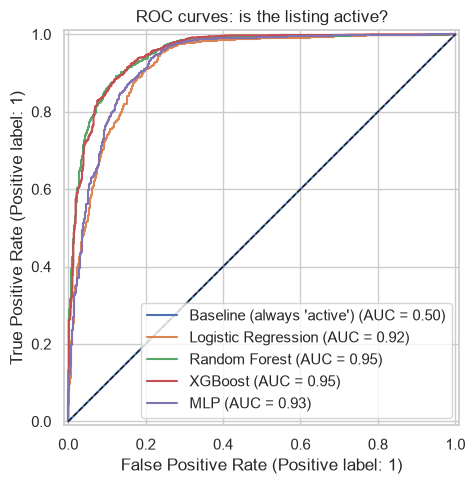

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set(title="ROC curves: is the listing active?")
plt.tight_layout(); plt.savefig(FIGS / "reliability_roc.png", dpi=120); plt.show()

In [5]:
BEST_NAME = max((k for k in results if not k.startswith("Baseline")), key=lambda k: results[k]["ROC_AUC"])
best = fitted[BEST_NAME]
print("best:", BEST_NAME)
print(classification_report(y_test, best.predict(X_test), digits=3))

best: XGBoost
              precision    recall  f1-score   support

           0      0.815     0.822     0.819       843
           1      0.937     0.934     0.936      2384

    accuracy                          0.905      3227
   macro avg      0.876     0.878     0.877      3227
weighted avg      0.905     0.905     0.905      3227



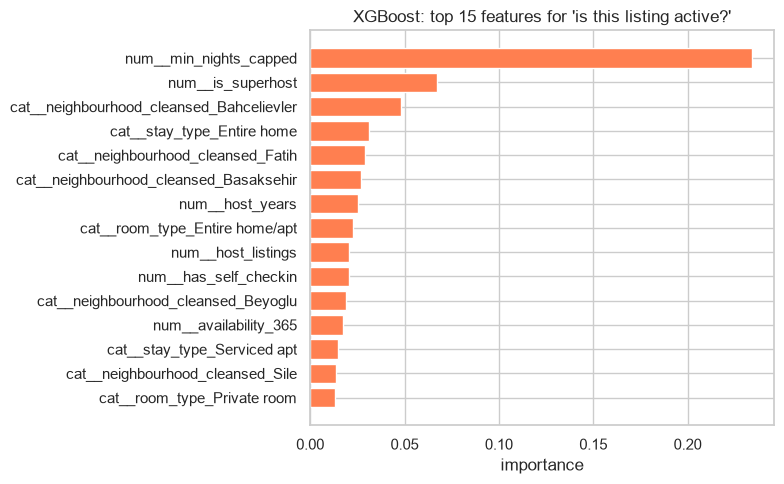

In [6]:
# What does the best model rely on? (proves there is no review leakage)
model = best.named_steps["model"]
names = best.named_steps["pre"].get_feature_names_out()
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=names)
else:   # logistic regression
    imp = pd.Series(np.abs(model.coef_[0]), index=names)
imp = imp.sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="coral")
ax.set(title=f"{BEST_NAME}: top 15 features for 'is this listing active?'", xlabel="importance")
plt.tight_layout(); plt.savefig(FIGS / "reliability_importance.png", dpi=120); plt.show()

**What I see:** _…_ (compare against the baseline row: always guessing 'active' already gets a high F1, but ROC-AUC 0.5)

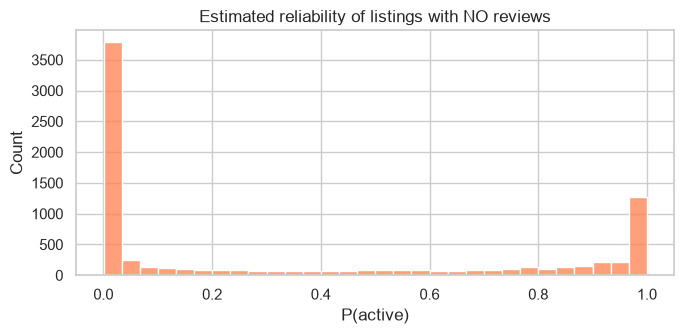

In [7]:
# Score every listing. Listings WITH history get out-of-fold scores, the rest get the final model.
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = cross_val_predict(best, X, y, cv=skf, method="predict_proba")[:, 1]
final = best.fit(X, y)
df["reliability"] = final.predict_proba(df[CAT + NUM])[:, 1]
df.loc[df["number_of_reviews"] > 0, "reliability"] = oof   # same row order as `hist`
joblib.dump(final, MODELS / "reliability_model.joblib")
df.to_parquet(PROCESSED / "listings_priced.parquet", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df.loc[df["number_of_reviews"] == 0, "reliability"], bins=30, ax=ax, color="coral")
ax.set(title="Estimated reliability of listings with NO reviews", xlabel="P(active)")
plt.tight_layout(); plt.savefig(FIGS / "reliability_no_reviews.png", dpi=120); plt.show()

### Summary (fill in)
- Best model: _…_ (ROC-AUC _…_)
- What makes a listing look active: _…_
- How the app uses it: Trust score for listings without reviews ("New listing · estimated reliability 72%")